In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

import zipfile
import os

zip_path = "/content/archive.zip"

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        files = z.namelist()
        print("Total files:", len(files))
        print("First 25 filenames:")
        for name in files[:25]:
            print(name)
else:
    print("ZIP file not found at:", zip_path)


Total files: 7200
First 25 filenames:
Testing/glioma/Te-gl_1.jpg
Testing/glioma/Te-gl_10.jpg
Testing/glioma/Te-gl_100.jpg
Testing/glioma/Te-gl_101.jpg
Testing/glioma/Te-gl_102.jpg
Testing/glioma/Te-gl_103.jpg
Testing/glioma/Te-gl_104.jpg
Testing/glioma/Te-gl_105.jpg
Testing/glioma/Te-gl_106.jpg
Testing/glioma/Te-gl_107.jpg
Testing/glioma/Te-gl_108.jpg
Testing/glioma/Te-gl_109.jpg
Testing/glioma/Te-gl_11.jpg
Testing/glioma/Te-gl_110.jpg
Testing/glioma/Te-gl_111.jpg
Testing/glioma/Te-gl_112.jpg
Testing/glioma/Te-gl_113.jpg
Testing/glioma/Te-gl_114.jpg
Testing/glioma/Te-gl_115.jpg
Testing/glioma/Te-gl_116.jpg
Testing/glioma/Te-gl_117.jpg
Testing/glioma/Te-gl_118.jpg
Testing/glioma/Te-gl_119.jpg
Testing/glioma/Te-gl_12.jpg
Testing/glioma/Te-gl_120.jpg


In [ ]:

import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/brain_tumor_dataset"

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)

print("Extraction complete!")
print("Folders:", os.listdir(extract_path))


Extraction complete!
Folders: ['Training', 'Testing']


In [ ]:

import os

for root, dirs, files in os.walk("/content/brain_tumor_dataset"):
    level = root.replace("/content/brain_tumor_dataset", "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + f" ({len(files)} files)")


brain_tumor_dataset (0 files)
  Training (0 files)
    glioma (1400 files)
    pituitary (1400 files)
    meningioma (1400 files)
    notumor (1400 files)
  Testing (0 files)
    glioma (400 files)
    pituitary (400 files)
    meningioma (400 files)
    notumor (400 files)


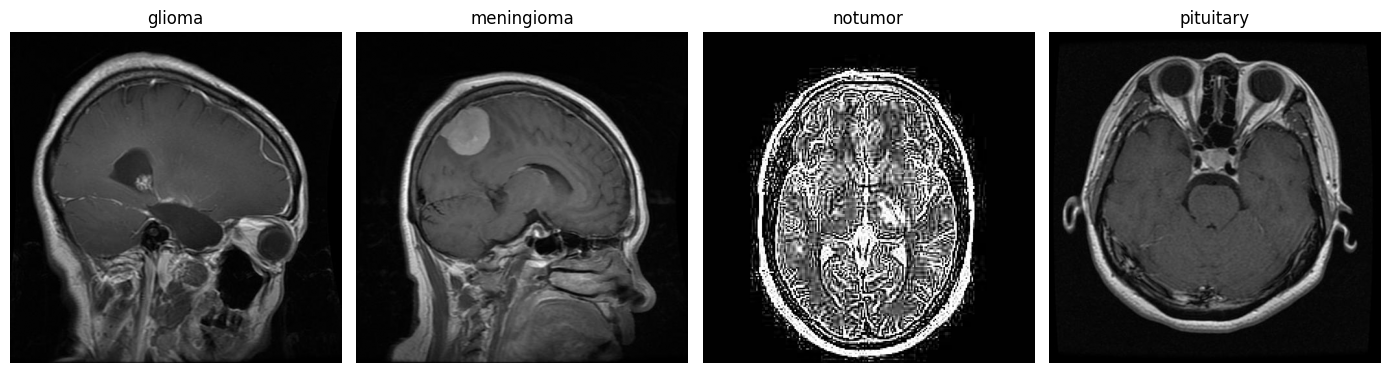

In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image

base_path = "/content/brain_tumor_dataset/Training"

classes = ["glioma", "meningioma", "notumor", "pituitary"]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, class_name in zip(axes, classes):
    folder = os.path.join(base_path, class_name)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    img = Image.open(os.path.join(folder, images[0]))
    ax.imshow(img, cmap="gray")
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import os
import tensorflow as tf

DATASET_DIR = "/content/brain_tumor_dataset"

# Locate the Training and Testing folders
for root, dirs, files in os.walk(DATASET_DIR):
    if "Training" in dirs and "Testing" in dirs:
        DATASET_DIR = root
        break

TRAIN_DIR = os.path.join(DATASET_DIR, "Training")
TEST_DIR = os.path.join(DATASET_DIR, "Testing")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.2,
    subset="training",
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.2,
    subset="validation",
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())


Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Training batches: 140
Validation batches: 35
Testing batches: 50


In [ ]:

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Datasets are ready for training.")


Datasets are ready for training.


In [ ]:

from tensorflow.keras import layers, models

def build_dilated_cnn(input_shape=(224, 224, 3), num_classes=4):
    inputs = layers.Input(shape=input_shape)

    x = layers.Rescaling(1.0 / 255)(inputs)

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        64, 3, padding="same", dilation_rate=2, activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        128, 3, padding="same", dilation_rate=2, activation="relu"
    )(x)

    x = layers.Conv2D(
        128, 3, padding="same", dilation_rate=4, activation="relu"
    )(x)

    x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return models.Model(inputs, outputs, name="Dilated_CNN")

dilated_model = build_dilated_cnn()

dilated_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

dilated_model.summary()


Model: "Dilated_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257,860 (1007.27 KB)

 Trainable params: 257,860 (1007.27 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

history_dilated = dilated_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)


Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 30s 109ms/step - accuracy: 0.4902 - loss: 1.1092 - val_accuracy: 0.6473 - val_loss: 0.8769
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 90ms/step - accuracy: 0.6556 - loss: 0.8464 - val_accuracy: 0.7089 - val_loss: 0.6953
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.7098 - loss: 0.7313 - val_accuracy: 0.7598 - val_loss: 0.5651
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 81ms/step - accuracy: 0.7585 - loss: 0.6316 - val_accuracy: 0.8152 - val_loss: 0.4936
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 81ms/step - accuracy: 0.7549 - loss: 0.6189 - val_accuracy: 0.7384 - val_loss: 0.6042
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 81ms/step - accuracy: 0.7587 - loss: 0.5909 - val_accuracy: 0.8152 - val_loss: 0.4785
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 91ms/step - accuracy: 0.7672 - loss: 0.5711 - val_accuracy: 0.8375 - val_loss: 0.4753
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 83ms/step - accuracy: 0.7833 - loss: 0.5513 -

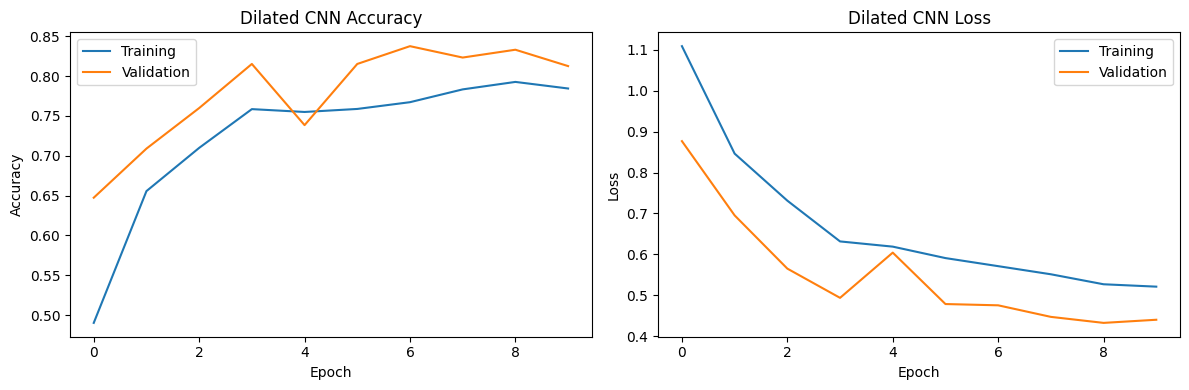

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_dilated.history["accuracy"], label="Training")
plt.plot(history_dilated.history["val_accuracy"], label="Validation")
plt.title("Dilated CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_dilated.history["loss"], label="Training")
plt.plot(history_dilated.history["val_loss"], label="Validation")
plt.title("Dilated CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step
Dilated CNN Test Results
              precision    recall  f1-score   support

      glioma       0.88      0.40      0.55       400
  meningioma       0.50      0.54      0.52       400
     notumor       0.65      0.97      0.78       400
   pituitary       0.87      0.84      0.86       400

    accuracy                           0.69      1600
   macro avg       0.72      0.69      0.68      1600
weighted avg       0.72      0.69      0.68      1600



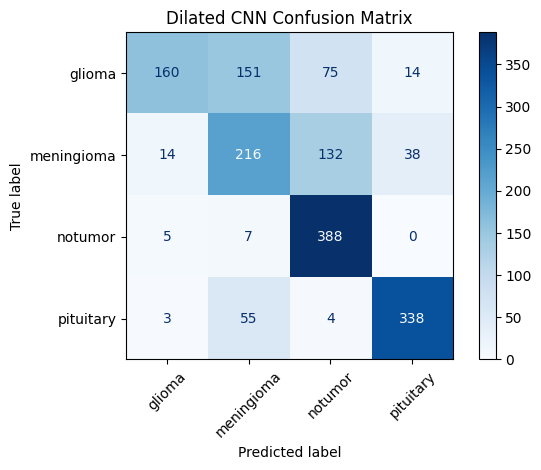

In [ ]:

import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = dilated_model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print("Dilated CNN Test Results")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Dilated CNN Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = layers.Lambda(preprocess_input)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

resnet_model = models.Model(inputs, outputs)

resnet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:

history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)


Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 32s 145ms/step - accuracy: 0.7895 - loss: 0.5529 - val_accuracy: 0.8946 - val_loss: 0.2893
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 116ms/step - accuracy: 0.8768 - loss: 0.3222 - val_accuracy: 0.9161 - val_loss: 0.2132
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 17s 119ms/step - accuracy: 0.9038 - loss: 0.2469 - val_accuracy: 0.9348 - val_loss: 0.1907
Epoch 4/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 117ms/step - accuracy: 0.9105 - loss: 0.2313 - val_accuracy: 0.9036 - val_loss: 0.2280
Epoch 5/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 114ms/step - accuracy: 0.9176 - loss: 0.2073 - val_accuracy: 0.9491 - val_loss: 0.1611
Epoch 6/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 127ms/step - accuracy: 0.9388 - loss: 0.1590 - val_accuracy: 0.9464 - val_loss: 0.1612
Epoch 7/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 114ms/step - accuracy: 0.9411 - loss: 0.1578 - val_accuracy: 0.9473 - val_loss: 0.1515
Epoch 8/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - accuracy: 0.9382 - loss: 0.1488 - 

50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 91ms/step
ResNet-50 Test Accuracy: 89.25 %

Classification Report:
              precision    recall  f1-score   support

      glioma       0.92      0.74      0.82       400
  meningioma       0.79      0.88      0.83       400
     notumor       0.91      0.99      0.95       400
   pituitary       0.97      0.96      0.96       400

    accuracy                           0.89      1600
   macro avg       0.90      0.89      0.89      1600
weighted avg       0.90      0.89      0.89      1600



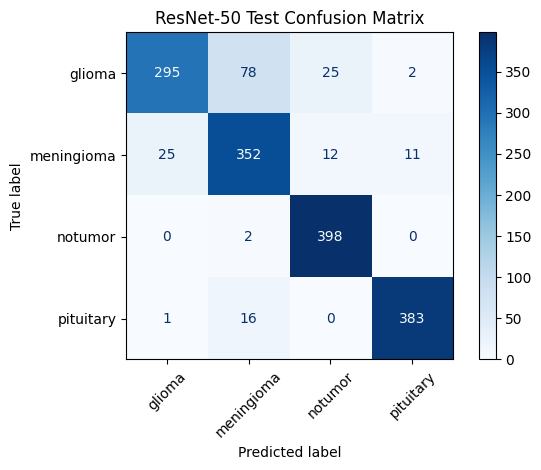

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob_resnet = resnet_model.predict(test_ds)
y_pred_resnet = np.argmax(y_prob_resnet, axis=1)

print("ResNet-50 Test Accuracy:",
      round(accuracy_score(y_true, y_pred_resnet) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred_resnet,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred_resnet,
    labels=range(len(class_names))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(cmap="Blues", xticks_rotation=45)

plt.title("ResNet-50 Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Dilated CNN predictions from its earlier test evaluation
y_prob_dilated = dilated_model.predict(test_ds)
y_pred_dilated = np.argmax(y_prob_dilated, axis=1)

results = []

for name, pred in [
    ("Dilated CNN", y_pred_dilated),
    ("ResNet-50", y_pred_resnet)
]:
    results.append({
        "Model": name,
        "Test Accuracy (%)": round(accuracy_score(y_true, pred) * 100, 2),
        "Precision (Macro)": round(precision_score(y_true, pred, average="macro", zero_division=0), 4),
        "Recall (Macro)": round(recall_score(y_true, pred, average="macro", zero_division=0), 4),
        "F1-score (Macro)": round(f1_score(y_true, pred, average="macro", zero_division=0), 4)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)


50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step


,Model,Test Accuracy (%),Precision (Macro),Recall (Macro),F1-score (Macro)
0,Dilated CNN,68.88,0.7243,0.6887,0.6759
1,ResNet-50,89.25,0.8967,0.8925,0.8910


In [ ]:

import os

save_dir = "/content/drive/MyDrive/BrainTumorProject"
os.makedirs(save_dir, exist_ok=True)

dilated_model.save(os.path.join(save_dir, "dilated_cnn.keras"))
resnet_model.save(os.path.join(save_dir, "resnet50.keras"))

print("Both models saved to Google Drive.")


Both models saved to Google Drive.


In [ ]:

import numpy as np
from sklearn.metrics import accuracy_score, classification_report

y_true = np.concatenate([y.numpy() for _, y in test_ds])

y_prob_resnet = resnet_model.predict(test_ds)
y_pred_resnet = np.argmax(y_prob_resnet, axis=1)

print("ResNet-50 Test Accuracy:",
      round(accuracy_score(y_true, y_pred_resnet) * 100, 2), "%")

print(classification_report(
    y_true, y_pred_resnet,
    target_names=class_names,
    zero_division=0
))


50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step
ResNet-50 Test Accuracy: 89.25 %
              precision    recall  f1-score   support

      glioma       0.92      0.74      0.82       400
  meningioma       0.79      0.88      0.83       400
     notumor       0.91      0.99      0.95       400
   pituitary       0.97      0.96      0.96       400

    accuracy                           0.89      1600
   macro avg       0.90      0.89      0.89      1600
weighted avg       0.90      0.89      0.89      1600



In [ ]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

y_prob_dilated = dilated_model.predict(test_ds)
y_pred_dilated = np.argmax(y_prob_dilated, axis=1)

results = []

for name, pred in [
    ("Dilated CNN", y_pred_dilated),
    ("ResNet-50", y_pred_resnet)
]:
    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_true, pred) * 100, 2),
        "Precision": round(precision_score(y_true, pred, average="macro", zero_division=0), 4),
        "Recall": round(recall_score(y_true, pred, average="macro", zero_division=0), 4),
        "F1-score": round(f1_score(y_true, pred, average="macro", zero_division=0), 4)
    })

display(pd.DataFrame(results))


50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step


,Model,Accuracy (%),Precision,Recall,F1-score
0,Dilated CNN,68.88,0.7243,0.6887,0.6759
1,ResNet-50,89.25,0.8967,0.8925,0.8910


Saving Screenshot 2026-10-24 141456.jpg to Screenshot 2026-10-24 141456.jpg


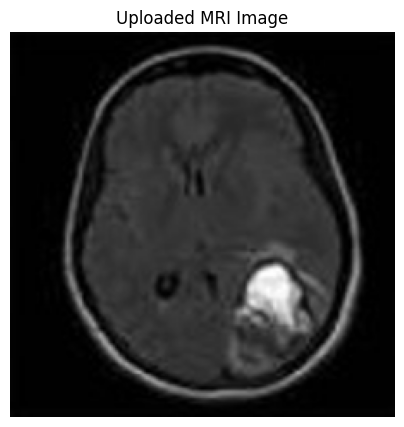

Dilated CNN Prediction: notumor
Model score: 66.18 %

ResNet-50 Prediction: meningioma
Model score: 97.18 %


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()
img_path = next(iter(uploaded))

img = Image.open(img_path).convert("RGB")

# Handle IMG_SIZE whether it is an integer or tuple
if isinstance(IMG_SIZE, (tuple, list)):
    target_size = (int(IMG_SIZE[0]), int(IMG_SIZE[1]))
else:
    target_size = (int(IMG_SIZE), int(IMG_SIZE))

img = img.resize(target_size)

img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Predict using both models
dilated_prob = dilated_model.predict(img_array, verbose=0)[0]
resnet_prob = resnet_model.predict(img_array, verbose=0)[0]

dilated_idx = np.argmax(dilated_prob)
resnet_idx = np.argmax(resnet_prob)

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title("Uploaded MRI Image")
plt.show()

print("Dilated CNN Prediction:", class_names[dilated_idx])
print("Model score:", round(float(dilated_prob[dilated_idx]) * 100, 2), "%")

print("\nResNet-50 Prediction:", class_names[resnet_idx])
print("Model score:", round(float(resnet_prob[resnet_idx]) * 100, 2), "%")


In [ ]:

print("Dilated CNN:")
for i, name in enumerate(class_names):
    print(f"{name}: {dilated_prob[i] * 100:.2f}%")

print("\nResNet-50:")
for i, name in enumerate(class_names):
    print(f"{name}: {resnet_prob[i] * 100:.2f}%")


Dilated CNN:
glioma: 0.03%
meningioma: 3.16%
notumor: 95.30%
pituitary: 1.51%

ResNet-50:
glioma: 0.02%
meningioma: 0.85%
notumor: 98.54%
pituitary: 0.60%


In [ ]:

for images, labels in train_ds.take(1):
    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))
    print("Image shape:", images.shape)


Minimum pixel value: 0.0
Maximum pixel value: 255.0
Image shape: (32, 224, 224, 3)


In [ ]:

print("Dilated CNN prediction scores:")
for name, score in zip(class_names, dilated_prob):
    print(f"{name}: {score * 100:.2f}%")

print("\nResNet-50 prediction scores:")
for name, score in zip(class_names, resnet_prob):
    print(f"{name}: {score * 100:.2f}%")


Dilated CNN prediction scores:
glioma: 0.03%
meningioma: 3.16%
notumor: 95.30%
pituitary: 1.51%

ResNet-50 prediction scores:
glioma: 0.02%
meningioma: 0.85%
notumor: 98.54%
pituitary: 0.60%



 Dilated CNN
              precision    recall  f1-score   support

      glioma       0.88      0.40      0.55       400
  meningioma       0.50      0.54      0.52       400
     notumor       0.65      0.97      0.78       400
   pituitary       0.87      0.84      0.86       400

    accuracy                           0.69      1600
   macro avg       0.72      0.69      0.68      1600
weighted avg       0.72      0.69      0.68      1600



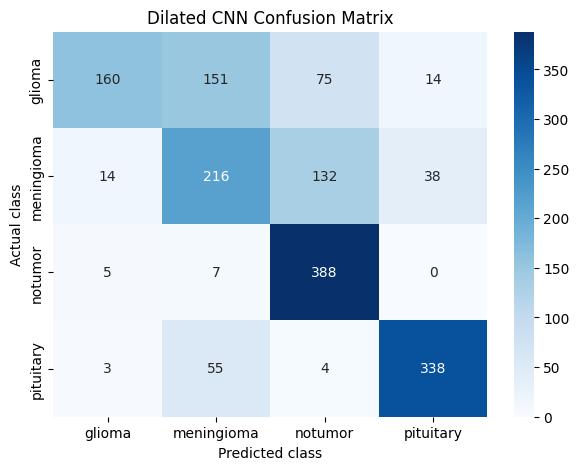


 ResNet-50
              precision    recall  f1-score   support

      glioma       0.92      0.74      0.82       400
  meningioma       0.79      0.88      0.83       400
     notumor       0.91      0.99      0.95       400
   pituitary       0.97      0.96      0.96       400

    accuracy                           0.89      1600
   macro avg       0.90      0.89      0.89      1600
weighted avg       0.90      0.89      0.89      1600



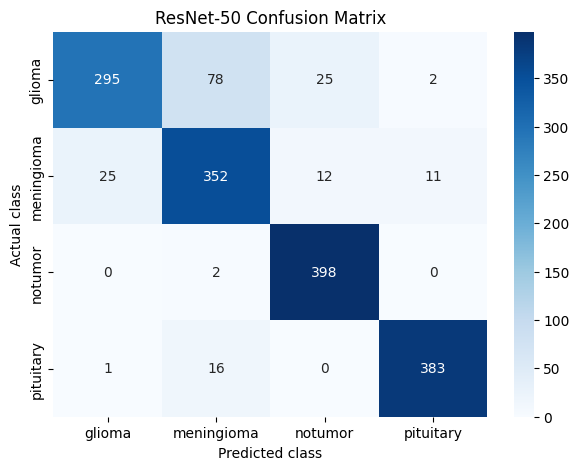

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_true = []
y_pred_dilated = []
y_pred_resnet = []

for images, labels in test_ds:
    pred_d = dilated_model.predict(images, verbose=0)
    pred_r = resnet_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred_dilated.extend(pred_d.argmax(axis=1))
    y_pred_resnet.extend(pred_r.argmax(axis=1))

y_true = __import__('numpy').array(y_true)
y_pred_dilated = __import__('numpy').array(y_pred_dilated)
y_pred_resnet = __import__('numpy').array(y_pred_resnet)

for name, predictions in [
    ("Dilated CNN", y_pred_dilated),
    ("ResNet-50", y_pred_resnet)
]:
    print("\n", name)
    print(classification_report(
        y_true, predictions,
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(y_true, predictions)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm, annot=True, fmt="d",
        xticklabels=class_names,
        yticklabels=class_names,
        cmap="Blues"
    )
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.title(name + " Confusion Matrix")
    plt.show()

In [ ]:
import os
import matplotlib.pyplot as plt

save_dir = "/content/drive/MyDrive/BrainTumorProject/results"
os.makedirs(save_dir, exist_ok=True)

# Save the currently displayed figures
for i, fig_num in enumerate(plt.get_fignums()):
    fig = plt.figure(fig_num)
    fig.savefig(
        os.path.join(save_dir, f"figure_{i+1}.png"),
        dpi=300,
        bbox_inches="tight"
    )

print("Figures saved to Google Drive.")

Figures saved to Google Drive.


In [ ]:
import os

save_dir = "/content/drive/MyDrive/BrainTumorProject"

for filename in ["dilated_cnn.keras", "resnet50.keras"]:
    path = os.path.join(save_dir, filename)
    print(filename, "Exists:", os.path.exists(path))

dilated_cnn.keras Exists: True
resnet50.keras Exists: True


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"],
    "Dilated CNN": [68.88, 0.72, 0.69, 0.68],
    "ResNet-50": [89.25, 0.90, 0.89, 0.89]
})

display(comparison)

comparison.to_csv(
    "/content/drive/MyDrive/BrainTumorProject/results/model_comparison.csv",
    index=False
)

,Metric,Dilated CNN,ResNet-50
0,Accuracy,68.88,89.25
1,Macro Precision,0.72,0.90
2,Macro Recall,0.69,0.89
3,Macro F1-score,0.68,0.89


In [ ]:
!pip -q install streamlit pyngrok

In [ ]:
%%writefile /content/app.py
import streamlit as st
import numpy as np
import tensorflow as tf
from PIL import Image

st.set_page_config(page_title="Brain Tumor Detection", page_icon="🧠")

st.title("Brain Tumor Detection Using Deep Learning")
st.write("Upload an MRI image to obtain experimental model predictions.")

model_choice = st.selectbox(
    "Select model",
    ["ResNet-50", "Dilated CNN"]
)

uploaded_file = st.file_uploader(
    "Upload brain MRI image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file:
    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption="Uploaded MRI Image", width=350)

    if st.button("Analyze Image"):
        with st.spinner("Analyzing image..."):
            model_path = (
                "/content/drive/MyDrive/BrainTumorProject/resnet50.keras"
                if model_choice == "ResNet-50"
                else "/content/drive/MyDrive/BrainTumorProject/dilated_cnn.keras"
            )

            model = tf.keras.models.load_model(model_path)

            image_size = (224, 224)
            img = image.resize(image_size)
            arr = np.array(img, dtype=np.float32)

            # Match the normalization used during training.
            arr = arr / 255.0
            prediction = model.predict(np.expand_dims(arr, axis=0), verbose=0)[0]

            classes = ["glioma", "meningioma", "notumor", "pituitary"]
            index = int(np.argmax(prediction))

            st.subheader("Prediction")
            st.write(f"Class: **{classes[index]}**")
            st.write(f"Model confidence: **{prediction[index] * 100:.2f}%**")

            st.warning(
                "This is an experimental AI prediction, not a medical diagnosis. "
                "Consult a qualified radiologist for interpretation."
            )

Writing /content/app.py


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [ ]:
import os

print("Drive folder exists:", os.path.isdir("/content/drive"))
print("MyDrive accessible:", os.path.isdir("/content/drive/MyDrive"))

Drive folder exists: True
MyDrive accessible: True


In [ ]:
import os

folder = "/content/drive/MyDrive/BrainTumorProject"

print(os.listdir(folder))

['resnet50.keras', 'results', 'dilated_cnn.keras']


In [ ]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501)
print(public_url)

ERROR:pyngrok.process.ngrok:t=2026-10-24T09:03:33+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2026-10-24T09:03:33+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [ ]:
!pip install -q pyngrok

from pyngrok import ngrok

ngrok.kill()
ngrok.set_auth_token("3L8PNzq44UIN4hksiQiVzvbPSs0_aQCo59gezNFb987nvSrJ")

public_url = ngrok.connect(8501)
print(public_url)

NgrokTunnel: "https://flatly-penniless-protrude.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
import time
import requests

time.sleep(5)

try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("Streamlit is running. Status:", response.status_code)
except Exception as e:
    print("Streamlit failed to start:", e)

print(open("/content/streamlit.log").read()[-3000:])

Streamlit is running. Status: 200


2026-10-24 09:34:08.310 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.16.138.27:8501




In [ ]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501)
print("Public URL:", public_url)

PyngrokNgrokHTTPError: ngrok client exception, API returned 502: {"error_code":103,"status_code":502,"msg":"failed to start tunnel","details":{"err":"failed to start tunnel: The endpoint 'https://flatly-penniless-protrude.ngrok-free.dev' is already online. Either\n1. stop your existing endpoint first, or\n2. start both endpoints with `--pooling-enabled` to load balance between them.\r\n\r\nERR_NGROK_334\r\n"}}


In [ ]:
import requests

try:
    r = requests.get("http://127.0.0.1:8501", timeout=5)
    print("Streamlit status:", r.status_code)
except Exception as e:
    print("Streamlit is not responding:", e)

Streamlit status: 200


In [ ]:
print(open("/content/streamlit.log").read()[-4000:])



2026-10-24 09:34:08.310 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.16.138.27:8501




In [ ]:
import os

print("App exists:", os.path.exists("/content/app.py"))
print("ResNet model exists:", os.path.exists(
    "/content/drive/MyDrive/BrainTumorProject/resnet50.keras"
))

App exists: True
ResNet model exists: True


In [ ]:
!pip install -q streamlit
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!curl -I http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Sat, 24 Oct 2026 09:38:15 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Sat, 24 Oct 2026 08:59:31 GMT
etag: "99905bf4faf4bdfe6bd768817deb297c"
cache-control: no-cache



In [ ]:

from pyngrok import ngrok

ngrok.kill()

public_url = ngrok.connect(8501)
print("Your public app URL:", public_url)


Your public app URL: NgrokTunnel: "https://flatly-penniless-protrude.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
import os

path = "/content/drive"

print("Exists:", os.path.exists(path))
print("Is symlink:", os.path.islink(path))
print("Contents:", os.listdir(path)[:20] if os.path.isdir(path) else "Not a directory")

Exists: True
Is symlink: False
Contents: ['MyDrive']


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))

['BrainTumorProject']


In [ ]:
import os

project = "/content/drive/MyDrive/BrainTumorProject"

print("Project folder exists:", os.path.isdir(project))

if os.path.isdir(project):
    print("Files found:")
    for file in os.listdir(project):
        print(file)

Project folder exists: True
Files found:
resnet50.keras
results
dilated_cnn.keras


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input

model_path = "/content/drive/MyDrive/BrainTumorProject/resnet50.keras"

model = tf.keras.models.load_model(
    model_path,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("ResNet-50 loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

ResNet-50 loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input

project = "/content/drive/MyDrive/BrainTumorProject"

for name in ["resnet50.keras", "dilated_cnn.keras"]:
    path = f"{project}/{name}"
    try:
        model = tf.keras.models.load_model(
            path,
            custom_objects={"preprocess_input": preprocess_input},
            compile=False
        )
        print(f"✅ {name}: Loaded successfully")
        print("Input:", model.input_shape)
        print("Output:", model.output_shape)
    except Exception as e:
        print(f"❌ {name}: {e}")

✅ resnet50.keras: Loaded successfully
Input: (None, 224, 224, 3)
Output: (None, 4)
✅ dilated_cnn.keras: Loaded successfully
Input: (None, 224, 224, 3)
Output: (None, 4)


In [ ]:
import shutil

shutil.copy(
    "/content/app.py",
    "/content/drive/MyDrive/BrainTumorProject/app.py"
)

print("App copied to project folder.")

App copied to project folder.


In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run /content/drive/MyDrive/BrainTumorProject/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [ ]:
!pip install -q streamlit pyngrok

In [ ]:
!streamlit run /content/drive/MyDrive/BrainTumorProject/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501).public_url

print("Your Brain Tumor Detection App:", public_url)

ModuleNotFoundError: No module named 'pyngrok'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project = "/content/drive/MyDrive/BrainTumorProject"
print(os.listdir(project))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BrainTumorProject'

In [ ]:
!pip install -q streamlit pyngrok

In [ ]:
!streamlit run /content/drive/MyDrive/BrainTumorProject/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
from pyngrok import ngrok

# Paste your ngrok Authtoken from https://dashboard.ngrok.com/get-started/your-authtoken
AUTHTOKEN = "YOUR_NGROK_AUTHTOKEN_HERE"
ngrok.set_auth_token(AUTHTOKEN)

ngrok.kill()
public_url = ngrok.connect(8501).public_url
print("Your public Streamlit app URL:", public_url)

ERROR:pyngrok.process.ngrok:t=2026-10-25T07:48:44+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n.

In [ ]:
from pyngrok import ngrok
from getpass import getpass

token = getpass("3L8PNzq44UIN4hksiQiVzvbPSs0_aQCo59gezNFb987nvSrJ ")
ngrok.set_auth_token(token.strip())

print("Authtoken configured.")

3L8PNzq44UIN4hksiQiVzvbPSs0_aQCo59gezNFb987nvSrJ ··········
Authtoken configured.


In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run /content/drive/MyDrive/BrainTumorProject/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!pip install -q pyngrok

from pyngrok import ngrok
from getpass import getpass

ngrok.kill()

token = getpass("Paste the token copied from ngrok: ").strip()

if not token or " " in token:
    raise ValueError("The token is empty or contains spaces.")

ngrok.set_auth_token(token)

print("Token configured. Now test the connection.")

Paste the token copied from ngrok: ··········
Token configured. Now test the connection.


In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(8501, "http").public_url
print("Your Brain Tumor Detection App:", public_url)

Your Brain Tumor Detection App: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
!streamlit run /content/drive/MyDrive/BrainTumorProject/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: /content/drive/MyDrive/BrainTumorProject/app.py


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    if "app.py" in files:
        print(os.path.join(root, "app.py"))

In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: /content/app.py


In [ ]:
import os

for base in ["/content/drive/MyDrive", "/content"]:
    if os.path.isdir(base):
        print(f"\nSearching in {base}...")
        for root, dirs, files in os.walk(base):
            dirs[:] = [d for d in dirs if d not in [
                ".git", "node_modules", "__pycache__"
            ]]
            if "app.py" in files:
                print("APP:", os.path.join(root, "app.py"))
            for name in ["resnet50.keras", "dilated_cnn.keras"]:
                if name in files:
                    print("MODEL:", os.path.join(root, name))


Searching in /content/drive/MyDrive...

Searching in /content...


In [ ]:
!streamlit run /content/drive/MyDrive/BrainTumorProject/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
import os

paths = [
    "/content/drive/MyDrive/BrainTumorProject",
    "/content/drive/MyDrive",
    "/content"
]

for path in paths:
    print(f"\nChecking: {path}")
    if os.path.exists(path):
        print(os.listdir(path)[:30])
    else:
        print("Path does not exist")


Checking: /content/drive/MyDrive/BrainTumorProject
Path does not exist

Checking: /content/drive/MyDrive
['Colab Notebooks']

Checking: /content
['.config', 'drive', 'streamlit.log', 'sample_data']


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks']


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive/BrainTumorProject'))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BrainTumorProject'

In [ ]:
import os

print("MyDrive contents:")
print(os.listdir("/content/drive/MyDrive"))

MyDrive contents:
['Colab Notebooks']


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [
        ".cache", "site-packages", "__pycache__"
    ]]

    for name in files:
        if name in [
            "app.py",
            "resnet50.keras",
            "dilated_cnn.keras"
        ]:
            print(os.path.join(root, name))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

print("Google Drive files:")
print(os.listdir('/content/drive/MyDrive'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive files:
['Colab Notebooks']


In [ ]:
import os

project = "/content/drive/MyDrive/BrainTumorProject"

if os.path.isdir(project):
    print("Project files:", os.listdir(project))
else:
    print("BrainTumorProject folder not found.")

BrainTumorProject folder not found.


In [ ]:
import os

for name in ["resnet50.keras", "dilated_cnn.keras", "app.py", "archive.zip"]:
    found = []

    for root, dirs, files in os.walk("/content"):
        dirs[:] = [d for d in dirs if d not in [
            "site-packages", ".cache", "__pycache__"
        ]]

        if name in files:
            found.append(os.path.join(root, name))

    print(f"\n{name}:")
    print("\n".join(found) if found else "Not found")


resnet50.keras:
Not found

dilated_cnn.keras:
Not found

app.py:
Not found

archive.zip:
Not found


In [ ]:
import os

print("ZIP exists:", os.path.exists("/content/archive.zip"))
print("Dataset folders:", os.listdir("/content") if os.path.exists("/content") else [])

ZIP exists: False
Dataset folders: ['.config', 'sample_data']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

data_dir = "/content/drive/MyDrive/archive (1)"
print("Exists:", os.path.exists(data_dir))
print("Contents:", os.listdir(data_dir))

Exists: True
Contents: ['Training', 'Testing']


In [ ]:
!cp -r "/content/drive/MyDrive/archive (1)" /content/dataset
print(os.listdir("/content/dataset"))

^C
['Training', 'archive (1)', 'Testing']


In [ ]:
import os

train_dir = "/content/dataset/Training"
test_dir  = "/content/dataset/Testing"

for d in [train_dir, test_dir]:
    print(d)
    for cls in os.listdir(d):
        print("  ", cls, ":", len(os.listdir(os.path.join(d, cls))), "images")

/content/dataset/Training
   glioma : 1400 images
   pituitary : 1400 images
   meningioma : 1400 images
   notumor : 0 images
/content/dataset/Testing
   glioma : 400 images
   pituitary : 400 images
   meningioma : 400 images
   notumor : 400 images


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q streamlit pyngrok

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/BrainTumorProject"))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BrainTumorProject'

In [ ]:
import glob
for p in glob.glob("/content/drive/MyDrive/**/*.keras", recursive=True):
    print(p)
for p in glob.glob("/content/drive/MyDrive/**/app.py", recursive=True):
    print(p)

In [ ]:
import os
print(os.listdir("/content/drive/MyDrive"))

['Colab Notebooks', 'archive (1)']


In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/Colab Notebooks"))

['Untitled0.ipynb', 'Brain_Tumor_Detection.ipynb']


In [ ]:
!cp -r "/content/drive/MyDrive/archive (1)" /content/dataset

In [ ]:
!cp -r "/content/drive/MyDrive/archive (1)" /content/dataset

In [ ]:
import os
os.makedirs("/content/drive/MyDrive/BrainTumorProject", exist_ok=True)

resnet_model.save("/content/drive/MyDrive/BrainTumorProject/resnet50.keras")
dilated_model.save("/content/drive/MyDrive/BrainTumorProject/dilated_cnn.keras")

NameError: name 'resnet_model' is not defined

In [ ]:
import tensorflow as tf
print([n for n, v in globals().items() if isinstance(v, tf.keras.Model)])

[]


In [ ]:
import os
print(os.path.exists("/content/dataset/Training"))

True


In [ ]:
import tensorflow as tf, os
IMG_SIZE = (224, 224); BATCH = 32
train_dir = "/content/dataset/Training"
test_dir  = "/content/dataset/Testing"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="training", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="categorical")
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="categorical")
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="categorical", shuffle=False)

class_names = train_ds.class_names
print(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

Found 4200 files belonging to 4 classes.
Using 3360 files for training.
Found 4200 files belonging to 4 classes.
Using 840 files for validation.
Found 1600 files belonging to 4 classes.
['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

base = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = layers.Lambda(preprocess_input)(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = models.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=10)
print("Test:", model.evaluate(test_ds))

os.makedirs("/content/drive/MyDrive/BrainTumorProject", exist_ok=True)
model.save("/content/drive/MyDrive/BrainTumorProject/resnet50.keras")
print(os.listdir("/content/drive/MyDrive/BrainTumorProject"))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 44s 210ms/step - accuracy: 0.7042 - loss: 0.7001 - val_accuracy: 0.8702 - val_loss: 0.3493
Epoch 2/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 17s 105ms/step - accuracy: 0.8420 - loss: 0.3939 - val_accuracy: 0.8976 - val_loss: 0.2808
Epoch 3/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - accuracy: 0.8714 - loss: 0.3263 - val_accuracy: 0.9071 - val_loss: 0.2539
Epoch 4/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.8824 - loss: 0.2956 - val_accuracy: 0.9143 - val_loss: 0.2397
Epoch 5/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 12s 112ms/step - accuracy: 0.8967 - loss: 0.2649 - val_accuracy: 0.9131 - val_loss: 0.2358
Epoch 6/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 12s 115ms/step - accuracy: 0.9039 - loss: 0.2526 - val_accuracy: 0.9238 - val_loss: 0.2244
Epoch 7/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - accuracy: 0.9095 - loss: 0.2342 - val_accuracy: 0.9262 - val_loss: 0.2147
Epoch 8/10
105/105 ━━━━━━━━━━━━━

In [ ]:
inp = layers.Input(shape=(224, 224, 3))
x = layers.Rescaling(1./255)(inp)
for filters, d in [(32, 1), (64, 2), (128, 4), (128, 8)]:
    x = layers.Conv2D(filters, 3, padding="same", dilation_rate=d, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
out = layers.Dense(len(class_names), activation="softmax")(x)
dilated = models.Model(inp, out)

dilated.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
dilated.fit(train_ds, validation_data=val_ds, epochs=15)
print("Test:", dilated.evaluate(test_ds))

dilated.save("/content/drive/MyDrive/BrainTumorProject/dilated_cnn.keras")
print(os.listdir("/content/drive/MyDrive/BrainTumorProject"))

Epoch 1/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 29s 111ms/step - accuracy: 0.7321 - loss: 0.6738 - val_accuracy: 0.3333 - val_loss: 1.4753
Epoch 2/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 9s 81ms/step - accuracy: 0.8259 - loss: 0.4442 - val_accuracy: 0.3548 - val_loss: 2.6912
Epoch 3/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 9s 82ms/step - accuracy: 0.8497 - loss: 0.3742 - val_accuracy: 0.3595 - val_loss: 2.9787
Epoch 4/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 9s 83ms/step - accuracy: 0.8741 - loss: 0.3204 - val_accuracy: 0.3798 - val_loss: 3.0889
Epoch 5/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 9s 82ms/step - accuracy: 0.8967 - loss: 0.2820 - val_accuracy: 0.7155 - val_loss: 1.0008
Epoch 6/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 10s 81ms/step - accuracy: 0.9125 - loss: 0.2384 - val_accuracy: 0.8179 - val_loss: 0.4626
Epoch 7/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 10s 81ms/step - accuracy: 0.9315 - loss: 0.1933 - val_accuracy: 0.5714 - val_loss: 1.9977
Epoch 8/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 8s 80ms/step - accuracy: 0.9405 - loss: 0.1699 - val_

In [ ]:
%%writefile /content/app.py
import streamlit as st
import numpy as np
import tensorflow as tf
from PIL import Image
from tensorflow.keras.applications.resnet50 import preprocess_input

DIR = "/content/drive/MyDrive/BrainTumorProject/"
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

@st.cache_resource
def load(name):
    return tf.keras.models.load_model(
        DIR + name,
        custom_objects={"preprocess_input": preprocess_input},
        safe_mode=False)

st.title("Brain Tumor MRI Classifier")
choice = st.selectbox("Model", ["ResNet-50", "Dilated CNN"])
file = st.file_uploader("Upload an MRI image", type=["jpg", "jpeg", "png"])

if file:
    img = Image.open(file).convert("RGB")
    st.image(img, caption="Uploaded MRI", use_container_width=True)
    arr = np.expand_dims(np.array(img.resize((224, 224)), dtype="float32"), 0)
    model = load("resnet50.keras" if choice == "ResNet-50" else "dilated_cnn.keras")
    probs = model.predict(arr)[0]
    st.subheader("Prediction: " + CLASSES[int(np.argmax(probs))])
    for c, p in zip(CLASSES, probs):
        st.write(f"{c}: {p*100:.2f}%")
        st.progress(float(p))

Overwriting /content/app.py


In [ ]:
!cp /content/app.py /content/drive/MyDrive/BrainTumorProject/app.py

In [ ]:
!pip install -q streamlit pyngrok

In [ ]:
from pyngrok import ngrok
import subprocess, time

ngrok.kill()
ngrok.set_auth_token("3L8PNzq44UIN4hksiQiVzvbPSs0_aQCo59gezNFb987nvSrJ")   # from dashboard.ngrok.com

subprocess.Popen(["streamlit", "run", "/content/app.py",
                  "--server.port", "8501", "--server.headless", "true"])
time.sleep(5)

print("Open this link:", ngrok.connect(8501))

Open this link: NgrokTunnel: "https://flatly-penniless-protrude.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
import numpy as np, pandas as pd, tensorflow as tf, os, time
from tensorflow.keras.applications.resnet50 import preprocess_input

DIR = "/content/drive/MyDrive/BrainTumorProject/"
OUT = DIR + "results/"; os.makedirs(OUT, exist_ok=True)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/dataset/Testing", image_size=(224, 224), batch_size=32,
    label_mode="categorical", shuffle=False)
class_names = test_ds.class_names
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])

files = {"ResNet-50": "resnet50.keras", "Dilated CNN": "dilated_cnn.keras"}
models = {n: tf.keras.models.load_model(DIR + f,
          custom_objects={"preprocess_input": preprocess_input}, safe_mode=False)
          for n, f in files.items()}
probs = {n: m.predict(test_ds, verbose=0) for n, m in models.items()}
print(class_names, "| test images:", len(y_true))

Found 1600 files belonging to 4 classes.
['glioma', 'meningioma', 'notumor', 'pituitary'] | test images: 1600



===== ResNet-50 =====
              precision    recall  f1-score   support

      glioma     0.8951    0.6825    0.7745       400
  meningioma     0.4220    0.9000    0.5746       400
     notumor     0.0000    0.0000    0.0000       400
   pituitary     0.8846    0.9775    0.9287       400

    accuracy                         0.6400      1600
   macro avg     0.5504    0.6400    0.5695      1600
weighted avg     0.5504    0.6400    0.5695      1600

glioma       sensitivity=0.6825  specificity=0.9733
meningioma   sensitivity=0.9000  specificity=0.5892
notumor      sensitivity=0.0000  specificity=1.0000
pituitary    sensitivity=0.9775  specificity=0.9575


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


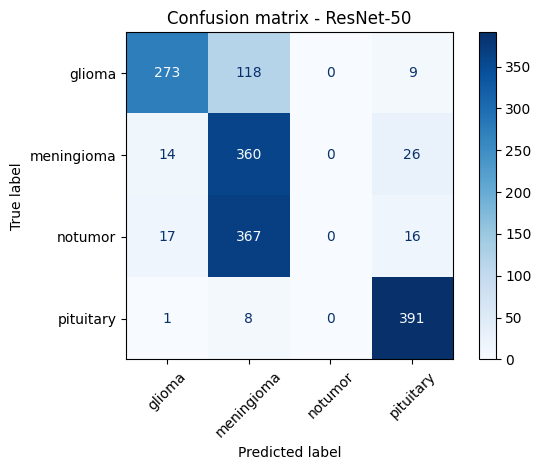


===== Dilated CNN =====
              precision    recall  f1-score   support

      glioma     0.9634    0.4600    0.6227       400
  meningioma     0.4000    0.9900    0.5698       400
     notumor     0.0000    0.0000    0.0000       400
   pituitary     0.8902    0.9325    0.9109       400

    accuracy                         0.5956      1600
   macro avg     0.5634    0.5956    0.5258      1600
weighted avg     0.5634    0.5956    0.5258      1600

glioma       sensitivity=0.4600  specificity=0.9942
meningioma   sensitivity=0.9900  specificity=0.5050
notumor      sensitivity=0.0000  specificity=1.0000
pituitary    sensitivity=0.9325  specificity=0.9617


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


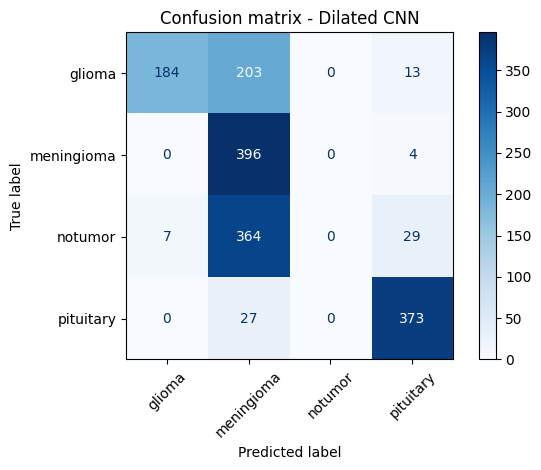

In [ ]:
from sklearn.metrics import (accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, f1_score)
import matplotlib.pyplot as plt

summary = {}
for n, p in probs.items():
    y_pred = p.argmax(1)
    cm = confusion_matrix(y_true, y_pred)

    print(f"\n===== {n} =====")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    # per-class sensitivity (recall) and specificity
    for i, c in enumerate(class_names):
        tp = cm[i, i]; fn = cm[i].sum() - tp
        fp = cm[:, i].sum() - tp; tn = cm.sum() - tp - fn - fp
        print(f"{c:12s} sensitivity={tp/(tp+fn):.4f}  specificity={tn/(tn+fp):.4f}")

    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
    plt.title(f"Confusion matrix - {n}"); plt.tight_layout()
    plt.savefig(OUT + f"cm_{n.replace(' ','_')}.png", dpi=200); plt.show()

    summary[n] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted"),
        "ROC-AUC (OvR)": roc_auc_score(y_true, p, multi_class="ovr"),
    }

In [ ]:
def benchmark(model, n_single=200, warmup=20):
    x1 = np.random.randint(0, 255, (1, 224, 224, 3)).astype("float32")
    for _ in range(warmup): model.predict(x1, verbose=0)       # warm-up (excluded)
    t = []
    for _ in range(n_single):
        s = time.perf_counter(); model.predict(x1, verbose=0)
        t.append((time.perf_counter() - s) * 1000)
    t = np.array(t)

    xb = np.random.randint(0, 255, (32, 224, 224, 3)).astype("float32")
    model.predict(xb, verbose=0)
    s = time.perf_counter()
    for _ in range(10): model.predict(xb, verbose=0)
    thr = (10 * 32) / (time.perf_counter() - s)
    return {"Latency mean (ms)": t.mean(), "Latency median (ms)": np.median(t),
            "Latency p95 (ms)": np.percentile(t, 95),
            "Throughput (img/s, batch 32)": thr}

for n, m in models.items():
    summary[n].update(benchmark(m))
    summary[n]["Parameters (M)"] = m.count_params() / 1e6
    summary[n]["File size (MB)"] = os.path.getsize(DIR + files[n]) / 1e6

In [ ]:
df = pd.DataFrame(summary).T.round(4)
display(df)
df.to_csv(OUT + "benchmark_summary.csv")

,Accuracy,Macro F1,Weighted F1,ROC-AUC (OvR),Latency mean (ms),Latency median (ms),Latency p95 (ms),"Throughput (img/s, batch 32)",Parameters (M),File size (MB)
ResNet-50,0.6400,0.5695,0.5695,0.8070,101.1660,89.5783,149.8332,172.9035,23.5959,95.1107
Dilated CNN,0.5956,0.5258,0.5258,0.7529,79.3554,70.8989,112.4490,256.2634,0.2428,2.9882


In [ ]:
%%writefile /content/drive/MyDrive/BrainTumorProject/launch.py
import subprocess, time
from pyngrok import ngrok
from google.colab import userdata

DIR = "/content/drive/MyDrive/BrainTumorProject/"
ngrok.kill()
ngrok.set_auth_token(userdata.get("NGROK_TOKEN"))

subprocess.Popen(["streamlit", "run", DIR + "app.py",
                  "--server.port", "8501", "--server.headless", "true"])
time.sleep(8)
print("OPEN THIS LINK:", ngrok.connect(8501).public_url)

Writing /content/drive/MyDrive/BrainTumorProject/launch.py


In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/BrainTumorProject"))

['resnet50.keras', 'dilated_cnn.keras', 'app.py', 'results', 'launch.py']


In [ ]:
!pip install -q streamlit pyngrok

In [ ]:
%%writefile /content/drive/MyDrive/BrainTumorProject/launch.py
import subprocess, time
from pyngrok import ngrok
from google.colab import userdata

DIR = "/content/drive/MyDrive/BrainTumorProject/"

subprocess.run(["pkill", "-f", "streamlit"])     # stop any old app still running
ngrok.kill()                                     # close any old ngrok link

try:
    ngrok.set_auth_token(userdata.get("NGROK_TOKEN"))
except Exception as e:
    print("Token note (safe to ignore):", str(e)[:80])

subprocess.Popen(["streamlit", "run", DIR + "app.py",
                  "--server.port", "8501", "--server.headless", "true"])
time.sleep(8)
print("OPEN THIS LINK:", ngrok.connect(8501).public_url)

Overwriting /content/drive/MyDrive/BrainTumorProject/launch.py


In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

Token note (safe to ignore): An error occurred when saving the auth token: b'Authtoken already set in configu
OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
!pkill -f streamlit

In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

Token note (safe to ignore): An error occurred when saving the auth token: b'Authtoken already set in configu
OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
%%writefile /content/drive/MyDrive/BrainTumorProject/app.py
import os, glob, time
import numpy as np, pandas as pd
import streamlit as st
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, roc_curve)
from tensorflow.keras.applications.resnet50 import preprocess_input

DIR = "/content/drive/MyDrive/BrainTumorProject/"
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
TEST_DIRS = ["/content/dataset/Testing", "/content/drive/MyDrive/archive (1)/Testing"]
MODEL_FILES = {os.path.basename(p): p for p in sorted(glob.glob(DIR + "*.keras"))}

st.set_page_config(page_title="Brain Tumor MRI Classifier", layout="wide")

@st.cache_resource
def load(path):
    return tf.keras.models.load_model(
        path, custom_objects={"preprocess_input": preprocess_input}, safe_mode=False)

def predict_one(model, img):
    arr = np.expand_dims(np.array(img.resize((224, 224)), dtype="float32"), 0)
    model(arr, training=False)                       # warm-up call (not timed)
    t = time.perf_counter()
    probs = model(arr, training=False).numpy()[0]
    return probs, (time.perf_counter() - t) * 1000

def find_test_dir():
    for d in TEST_DIRS:
        if os.path.isdir(d):
            return d
    return None

def run_benchmark(path):
    model = load(path)
    ds = tf.keras.utils.image_dataset_from_directory(
        find_test_dir(), image_size=(224, 224), batch_size=32,
        label_mode="int", shuffle=False)
    names = ds.class_names
    n = len(names)
    y_true = np.concatenate([y.numpy() for _, y in ds])
    probs = model.predict(ds, verbose=0)
    y_pred = probs.argmax(1)

    cm = confusion_matrix(y_true, y_pred, labels=range(n))
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(n), zero_division=0)
    spec = []
    for i in range(n):
        tp = cm[i, i]; fp = cm[:, i].sum() - tp
        fn = cm[i].sum() - tp; tn = cm.sum() - tp - fp - fn
        spec.append(tn / (tn + fp))
    per_class = pd.DataFrame({"Class": names, "Precision": p, "Recall (Sensitivity)": r,
                              "Specificity": spec, "F1-score": f, "Test images": s})

    # ROC curves (one class vs the rest)
    rocs = {}
    for i, c in enumerate(names):
        fpr, tpr, _ = roc_curve((y_true == i).astype(int), probs[:, i])
        rocs[c] = (fpr, tpr)

    # Latency: single image
    x1 = np.random.randint(0, 255, (1, 224, 224, 3)).astype("float32")
    for _ in range(20): model(x1, training=False)
    ts = []
    for _ in range(100):
        t0 = time.perf_counter(); model(x1, training=False).numpy()
        ts.append((time.perf_counter() - t0) * 1000)
    # Throughput: batch of 32
    xb = np.random.randint(0, 255, (32, 224, 224, 3)).astype("float32")
    model(xb, training=False)
    t0 = time.perf_counter()
    for _ in range(10): model(xb, training=False).numpy()
    thr = 320 / (time.perf_counter() - t0)

    summary = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": p.mean(), "Macro Recall": r.mean(), "Macro F1": f.mean(),
        "ROC-AUC (OvR)": roc_auc_score(y_true, probs, multi_class="ovr"),
        "Test images": len(y_true), "Misclassified": int((y_true != y_pred).sum()),
        "Latency mean (ms)": float(np.mean(ts)), "Latency median (ms)": float(np.median(ts)),
        "Latency p95 (ms)": float(np.percentile(ts, 95)),
        "Throughput (img/s)": thr,
        "Parameters (M)": model.count_params() / 1e6,
        "File size (MB)": os.path.getsize(path) / 1e6,
    }
    return {"summary": summary, "per_class": per_class, "cm": cm, "names": names, "rocs": rocs}

def show_results(res):
    summ = pd.DataFrame({n: r["summary"] for n, r in res.items()}).T
    st.subheader("Summary of all models")
    st.dataframe(summ.round(4), use_container_width=True)
    st.download_button("Download summary as CSV", summ.to_csv().encode(), "benchmark_summary.csv")
    st.caption("Accuracy / F1 / ROC-AUC comparison")
    st.bar_chart(summ[["Accuracy", "Macro F1", "ROC-AUC (OvR)"]])

    for name, r in res.items():
        s = r["summary"]
        st.divider()
        st.header(name)
        a = st.columns(4)
        a[0].metric("Accuracy", f"{s['Accuracy']*100:.2f}%")
        a[1].metric("Macro F1", f"{s['Macro F1']:.4f}")
        a[2].metric("ROC-AUC", f"{s['ROC-AUC (OvR)']:.4f}")
        a[3].metric("Misclassified", f"{s['Misclassified']} / {s['Test images']}")
        b = st.columns(4)
        b[0].metric("Latency mean", f"{s['Latency mean (ms)']:.1f} ms")
        b[1].metric("Latency p95", f"{s['Latency p95 (ms)']:.1f} ms")
        b[2].metric("Throughput", f"{s['Throughput (img/s)']:.1f} img/s")
        b[3].metric("Model size", f"{s['File size (MB)']:.1f} MB")

        st.subheader("Per-class metrics")
        st.dataframe(r["per_class"].round(4), use_container_width=True)

        left, right = st.columns(2)
        names, cm = r["names"], r["cm"]
        fig, ax = plt.subplots(figsize=(5, 4.5))
        ax.imshow(cm, cmap="Blues")
        ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right")
        ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
        for i in range(len(names)):
            for j in range(len(names)):
                ax.text(j, i, cm[i, j], ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix")
        fig.tight_layout(); left.pyplot(fig); plt.close(fig)

        fig, ax = plt.subplots(figsize=(5, 4.5))
        for c, (fpr, tpr) in r["rocs"].items():
            ax.plot(fpr, tpr, label=c)
        ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
        ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
        ax.set_title("ROC curves (one class vs rest)"); ax.legend()
        fig.tight_layout(); right.pyplot(fig); plt.close(fig)

# ------------------------------ PAGE ------------------------------
st.title("Brain Tumor MRI Classifier")
st.caption("For educational purposes only. Not a medical diagnosis tool.")

if not MODEL_FILES:
    st.error("No .keras model files found in " + DIR)
    st.stop()

tab1, tab2 = st.tabs(["Predict", "Benchmark"])

with tab1:
    choice = st.selectbox("Model", list(MODEL_FILES))
    file = st.file_uploader("Upload an MRI image", type=["jpg", "jpeg", "png"])
    if file:
        img = Image.open(file).convert("RGB")
        c1, c2 = st.columns(2)
        c1.image(img, caption="Uploaded MRI", use_container_width=True)
        if c2.button("Predict", type="primary"):
            with st.spinner("Running the model..."):
                probs, ms = predict_one(load(MODEL_FILES[choice]), img)
            idx = int(probs.argmax())
            c2.metric("Predicted class", CLASSES[idx])
            c2.metric("Confidence", f"{probs[idx]*100:.2f}%")
            c2.metric("Inference time", f"{ms:.1f} ms")
            dfp = pd.DataFrame({"Class": CLASSES, "Probability (%)": probs * 100})
            c2.dataframe(dfp.round(2), use_container_width=True)
            c2.bar_chart(dfp.set_index("Class"))

with tab2:
    test_dir = find_test_dir()
    if not test_dir:
        st.error("Test folder not found. Make sure Drive is mounted and 'archive (1)/Testing' exists.")
    else:
        st.write("Test folder:", test_dir)
        sel = st.multiselect("Models to benchmark", list(MODEL_FILES), default=list(MODEL_FILES))
        if st.button("Run benchmark", type="primary") and sel:
            res, bar = {}, st.progress(0.0)
            for i, n in enumerate(sel):
                with st.spinner(f"Benchmarking {n} ..."):
                    res[n] = run_benchmark(MODEL_FILES[n])
                bar.progress((i + 1) / len(sel))
            st.session_state["bench"] = res
            os.makedirs(DIR + "results", exist_ok=True)
            pd.DataFrame({n: r["summary"] for n, r in res.items()}).T.to_csv(
                DIR + "results/benchmark_summary.csv")
        if "bench" in st.session_state:
            show_results(st.session_state["bench"])

Overwriting /content/drive/MyDrive/BrainTumorProject/app.py


In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

Token note (safe to ignore): An error occurred when saving the auth token: b'Authtoken already set in configu
OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
%%writefile /content/drive/MyDrive/BrainTumorProject/cli.py
import os, sys, glob, time, argparse
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # hide TensorFlow's noisy messages
import numpy as np, pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score)
from tensorflow.keras.applications.resnet50 import preprocess_input

DIR = "/content/drive/MyDrive/BrainTumorProject/"
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
TEST_DIRS = ["/content/dataset/Testing", "/content/drive/MyDrive/archive (1)/Testing"]
MODEL_FILES = {os.path.basename(p): p for p in sorted(glob.glob(DIR + "*.keras"))}
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)

LINES = []
def out(s=""):
    print(s); LINES.append(str(s))
def banner(t):
    out("\n" + "=" * 72); out(t); out("=" * 72)

def load(path):
    return tf.keras.models.load_model(
        path, custom_objects={"preprocess_input": preprocess_input}, safe_mode=False)

def check_models(names):
    for n in names:
        if n not in MODEL_FILES:
            print(f"Model '{n}' not found. Available: {list(MODEL_FILES)}"); sys.exit(1)

# ---------------------------- PREDICT ----------------------------
def cmd_predict(a):
    if not os.path.isfile(a.image):
        print("Image not found:", a.image); sys.exit(1)
    names = list(MODEL_FILES) if a.model == "all" else [a.model]
    check_models(names)
    img = Image.open(a.image).convert("RGB")
    arr = np.expand_dims(np.array(img.resize((224, 224)), dtype="float32"), 0)
    out(f"Image: {a.image}")
    for n in names:
        model = load(MODEL_FILES[n])
        model(arr, training=False)                       # warm-up (not timed)
        t = time.perf_counter()
        probs = model(arr, training=False).numpy()[0]
        ms = (time.perf_counter() - t) * 1000
        idx = int(probs.argmax())
        banner(f"Model: {n}")
        out(f"Predicted class : {CLASSES[idx]}")
        out(f"Confidence      : {probs[idx]*100:.2f}%")
        out(f"Inference time  : {ms:.1f} ms")
        out("Probabilities:")
        for c, p in zip(CLASSES, probs):
            out(f"  {c:12s} {p*100:6.2f}%  {'#' * int(p * 40)}")

# --------------------------- BENCHMARK ---------------------------
def cmd_benchmark(a):
    names = a.models if a.models else list(MODEL_FILES)
    check_models(names)
    test_dir = next((d for d in TEST_DIRS if os.path.isdir(d)), None)
    if not test_dir:
        print("Test folder not found. Mount Drive and check 'archive (1)/Testing'."); sys.exit(1)

    gpus = tf.config.list_physical_devices("GPU")
    banner("BENCHMARK SETUP")
    out(f"Test folder : {test_dir}")
    out(f"Hardware    : {'GPU (' + str(len(gpus)) + ' device)' if gpus else 'CPU only'}")
    out(f"Models      : {', '.join(names)}")

    ds = tf.keras.utils.image_dataset_from_directory(
        test_dir, image_size=(224, 224), batch_size=32, label_mode="int", shuffle=False)
    cls = ds.class_names; n = len(cls)
    ds = ds.cache().prefetch(tf.data.AUTOTUNE)
    y_true = np.concatenate([y.numpy() for _, y in ds])
    out(f"Test images : {len(y_true)}   Classes: {cls}")

    rows = {}
    for name in names:
        path = MODEL_FILES[name]
        model = load(path)
        banner(f"MODEL: {name}")
        probs = model.predict(ds, verbose=0)
        y_pred = probs.argmax(1)

        cm = confusion_matrix(y_true, y_pred, labels=range(n))
        p, r, f, s = precision_recall_fscore_support(
            y_true, y_pred, labels=range(n), zero_division=0)
        spec, auc = [], []
        for i in range(n):
            tp = cm[i, i]; fp = cm[:, i].sum() - tp
            fn = cm[i].sum() - tp; tn = cm.sum() - tp - fp - fn
            spec.append(tn / (tn + fp))
            auc.append(roc_auc_score((y_true == i).astype(int), probs[:, i]))
        per_class = pd.DataFrame({"Precision": p, "Recall(Sens.)": r, "Specificity": spec,
                                  "F1": f, "AUC": auc, "Images": s}, index=cls).round(4)

        # latency (single image) and throughput (batch of 32)
        x1 = np.random.randint(0, 255, (1, 224, 224, 3)).astype("float32")
        for _ in range(20): model(x1, training=False)
        ts = []
        for _ in range(100):
            t0 = time.perf_counter(); model(x1, training=False).numpy()
            ts.append((time.perf_counter() - t0) * 1000)
        xb = np.random.randint(0, 255, (32, 224, 224, 3)).astype("float32")
        model(xb, training=False)
        t0 = time.perf_counter()
        for _ in range(10): model(xb, training=False).numpy()
        thr = 320 / (time.perf_counter() - t0)

        acc = accuracy_score(y_true, y_pred)
        rows[name] = {
            "Accuracy": acc, "Macro Precision": p.mean(), "Macro Recall": r.mean(),
            "Macro F1": f.mean(), "ROC-AUC (OvR)": roc_auc_score(y_true, probs, multi_class="ovr"),
            "Misclassified": int((y_true != y_pred).sum()), "Test images": len(y_true),
            "Latency mean (ms)": np.mean(ts), "Latency median (ms)": np.median(ts),
            "Latency p95 (ms)": np.percentile(ts, 95), "Throughput (img/s)": thr,
            "Parameters (M)": model.count_params() / 1e6,
            "File size (MB)": os.path.getsize(path) / 1e6}

        out(f"Accuracy         : {acc*100:.2f}%")
        out(f"Macro F1         : {rows[name]['Macro F1']:.4f}")
        out(f"ROC-AUC (OvR)    : {rows[name]['ROC-AUC (OvR)']:.4f}")
        out(f"Misclassified    : {rows[name]['Misclassified']} of {len(y_true)}")
        out(f"Latency (1 img)  : mean {np.mean(ts):.1f} ms | median {np.median(ts):.1f} ms | p95 {np.percentile(ts,95):.1f} ms")
        out(f"Throughput       : {thr:.1f} images/s (batch of 32)")
        out(f"Size             : {rows[name]['Parameters (M)']:.2f} M parameters, {rows[name]['File size (MB)']:.1f} MB")
        out("\nPer-class metrics:"); out(per_class.to_string())
        out("\nConfusion matrix (rows = true class, columns = predicted class):")
        out(pd.DataFrame(cm, index=cls, columns=cls).to_string())

    banner("COMPARISON OF ALL MODELS")
    summary = pd.DataFrame(rows).T
    out(summary.round(4).T.to_string())

    os.makedirs(DIR + "results", exist_ok=True)
    summary.to_csv(DIR + "results/benchmark_summary.csv")
    with open(DIR + "results/benchmark_report.txt", "w") as fh:
        fh.write("\n".join(LINES))
    out("\nSaved: results/benchmark_summary.csv and results/benchmark_report.txt in BrainTumorProject")

# ------------------------------ MAIN ------------------------------
if __name__ == "__main__":
    ap = argparse.ArgumentParser(description="Brain tumor classifier - terminal version")
    sub = ap.add_subparsers(dest="cmd", required=True)
    pp = sub.add_parser("predict", help="classify one MRI image")
    pp.add_argument("image"); pp.add_argument("--model", default="all")
    bp = sub.add_parser("benchmark", help="evaluate models on the Testing folder")
    bp.add_argument("--models", nargs="*")
    a = ap.parse_args()
    if not MODEL_FILES:
        print("No .keras models found in", DIR); sys.exit(1)
    cmd_predict(a) if a.cmd == "predict" else cmd_benchmark(a)

Writing /content/drive/MyDrive/BrainTumorProject/cli.py


In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import shutil
p = "/content/drive/MyDrive/BrainTumorProject/app.py"
shutil.copy(p, "/content/drive/MyDrive/BrainTumorProject/app_with_benchmark.py")   # backup

s = open(p).read()
s = s.split("with tab2:")[0]                                  # drop the Benchmark part
s = s.replace('tab1, tab2 = st.tabs(["Predict", "Benchmark"])', 'tab1, = st.tabs(["Predict"])')
open(p, "w").write(s)

7204

In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

Token note (safe to ignore): An error occurred when saving the auth token: b'Authtoken already set in configu
OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
!python /content/drive/MyDrive/BrainTumorProject/cli.py benchmark


BENCHMARK SETUP
Test folder : /content/dataset/Testing
Hardware    : GPU (1 device)
Models      : dilated_cnn.keras, resnet50.keras
Found 1600 files belonging to 4 classes.
Test images : 1600   Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

MODEL: dilated_cnn.keras
Accuracy         : 59.56%
Macro F1         : 0.5258
ROC-AUC (OvR)    : 0.7529
Misclassified    : 647 of 1600
Latency (1 img)  : mean 23.7 ms | median 22.6 ms | p95 31.7 ms
Throughput       : 553.2 images/s (batch of 32)
Size             : 0.24 M parameters, 3.0 MB

Per-class metrics:
            Precision  Recall(Sens.)  Specificity      F1     AUC  Images
glioma         0.9634         0.4600       0.9942  0.6227  0.8665     400
meningioma     0.4000         0.9900       0.5050  0.5698  0.8242     400
notumor        0.0000         0.0000       1.0000  0.0000  0.3329     400
pituitary      0.8902         0.9325       0.9617  0.9109  0.9879     400

Confusion matrix (rows = true class, columns = predicted class):


In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/BrainTumorProject"))
print(os.listdir("/content/drive/MyDrive/BrainTumorProject/results"))

['resnet50.keras', 'dilated_cnn.keras', 'app.py', 'results', 'launch.py', 'cli.py', 'app_with_benchmark.py']
['cm_ResNet-50.png', 'cm_Dilated_CNN.png', 'benchmark_summary.csv', 'benchmark_report.txt']


In [ ]:
!python /content/drive/MyDrive/BrainTumorProject/cli.py benchmark


BENCHMARK SETUP
Test folder : /content/dataset/Testing
Hardware    : GPU (1 device)
Models      : dilated_cnn.keras, resnet50.keras
Found 1600 files belonging to 4 classes.
Test images : 1600   Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

MODEL: dilated_cnn.keras
Accuracy         : 59.56%
Macro F1         : 0.5258
ROC-AUC (OvR)    : 0.7529
Misclassified    : 647 of 1600
Latency (1 img)  : mean 22.4 ms | median 21.9 ms | p95 25.8 ms
Throughput       : 539.4 images/s (batch of 32)
Size             : 0.24 M parameters, 3.0 MB

Per-class metrics:
            Precision  Recall(Sens.)  Specificity      F1     AUC  Images
glioma         0.9634         0.4600       0.9942  0.6227  0.8665     400
meningioma     0.4000         0.9900       0.5050  0.5698  0.8242     400
notumor        0.0000         0.0000       1.0000  0.0000  0.3329     400
pituitary      0.8902         0.9325       0.9617  0.9109  0.9879     400

Confusion matrix (rows = true class, columns = predicted class):


In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import shutil
p = "/content/drive/MyDrive/BrainTumorProject/app.py"
shutil.copy(p, "/content/drive/MyDrive/BrainTumorProject/app_with_benchmark.py")   # backup

s = open(p).read()
s = s.split("with tab2:")[0]                                  # drop the Benchmark part
s = s.replace('tab1, tab2 = st.tabs(["Predict", "Benchmark"])', 'tab1, = st.tabs(["Predict"])')
open(p, "w").write(s)

7204

In [ ]:
!pip install -q pyngrok streamlit

In [ ]:
from pyngrok import ngrok
from google.colab import userdata

print("pyngrok installed successfully")

pyngrok installed successfully


In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

Token note (safe to ignore): An error occurred when saving the auth token: b'Authtoken already set in configu
OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
!python /content/drive/MyDrive/BrainTumorProject/cli.py benchmark


BENCHMARK SETUP
Test folder : /content/drive/MyDrive/archive (1)/Testing
Hardware    : GPU (1 device)
Models      : dilated_cnn.keras, resnet50.keras
Found 1600 files belonging to 4 classes.
Test images : 1600   Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

MODEL: dilated_cnn.keras
Traceback (most recent call last):
  File "/content/drive/MyDrive/BrainTumorProject/cli.py", line 151, in <module>
    cmd_predict(a) if a.cmd == "predict" else cmd_benchmark(a)
                                              ~~~~~~~~~~~~~^^^
  File "/content/drive/MyDrive/BrainTumorProject/cli.py", line 81, in cmd_benchmark
    probs = model.predict(ds, verbose=0)
  File "/usr/local/lib/python3.13/dist-packages/keras/src/utils/traceback_utils.py", line 117, in error_handler
    return fn(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py", line 588, in predict
    batch_outputs = self.predict_function(data)
  File "/usr/local/lib/python3.13/d

In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

Token note (safe to ignore): An error occurred when saving the auth token: b'Authtoken already set in configu
OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
!python /content/drive/MyDrive/BrainTumorProject/cli.py benchmark


BENCHMARK SETUP
Test folder : /content/drive/MyDrive/archive (1)/Testing
Hardware    : GPU (1 device)
Models      : dilated_cnn.keras, resnet50.keras
Found 1600 files belonging to 4 classes.
Test images : 1600   Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

MODEL: dilated_cnn.keras
Accuracy         : 59.56%
Macro F1         : 0.5258
ROC-AUC (OvR)    : 0.7529
Misclassified    : 647 of 1600
Latency (1 img)  : mean 22.3 ms | median 21.0 ms | p95 32.3 ms
Throughput       : 556.3 images/s (batch of 32)
Size             : 0.24 M parameters, 3.0 MB

Per-class metrics:
            Precision  Recall(Sens.)  Specificity      F1     AUC  Images
glioma         0.9634         0.4600       0.9942  0.6227  0.8665     400
meningioma     0.4000         0.9900       0.5050  0.5698  0.8242     400
notumor        0.0000         0.0000       1.0000  0.0000  0.3329     400
pituitary      0.8902         0.9325       0.9617  0.9109  0.9879     400

Confusion matrix (rows = true class, columns = 

In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q pyngrok streamlit

In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

Token note (safe to ignore): An error occurred when saving the auth token: b'Authtoken already set in configu
OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py


Token note (safe to ignore): An error occurred when saving the auth token: b'Authtoken already set in configu
OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
!python /content/drive/MyDrive/BrainTumorProject/cli.py benchmark


BENCHMARK SETUP
Test folder : /content/drive/MyDrive/archive (1)/Testing
Hardware    : GPU (1 device)
Models      : dilated_cnn.keras, resnet50.keras
Found 1600 files belonging to 4 classes.


In [ ]:
!python /content/drive/MyDrive/BrainTumorProject/cli.py benchmark


BENCHMARK SETUP
Test folder : /content/drive/MyDrive/archive (1)/Testing
Hardware    : GPU (1 device)
Models      : dilated_cnn.keras, resnet50.keras
Found 1600 files belonging to 4 classes.
Test images : 1600   Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

MODEL: dilated_cnn.keras
Accuracy         : 59.56%
Macro F1         : 0.5258
ROC-AUC (OvR)    : 0.7529
Misclassified    : 647 of 1600
Latency (1 img)  : mean 25.8 ms | median 24.7 ms | p95 31.9 ms
Throughput       : 515.7 images/s (batch of 32)
Size             : 0.24 M parameters, 3.0 MB

Per-class metrics:
            Precision  Recall(Sens.)  Specificity      F1     AUC  Images
glioma         0.9634         0.4600       0.9942  0.6227  0.8665     400
meningioma     0.4000         0.9900       0.5050  0.5698  0.8242     400
notumor        0.0000         0.0000       1.0000  0.0000  0.3329     400
pituitary      0.8902         0.9325       0.9617  0.9109  0.9879     400

Confusion matrix (rows = true class, columns = 

In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q pyngrok streamlit

In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
!python /content/drive/MyDrive/BrainTumorProject/cli.py benchmark


BENCHMARK SETUP
Test folder : /content/drive/MyDrive/archive (1)/Testing
Hardware    : GPU (1 device)
Models      : dilated_cnn.keras, resnet50.keras
Found 1600 files belonging to 4 classes.
Test images : 1600   Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

MODEL: dilated_cnn.keras
Accuracy         : 59.56%
Macro F1         : 0.5258
ROC-AUC (OvR)    : 0.7529
Misclassified    : 647 of 1600
Latency (1 img)  : mean 24.3 ms | median 23.4 ms | p95 31.9 ms
Throughput       : 518.6 images/s (batch of 32)
Size             : 0.24 M parameters, 3.0 MB

Per-class metrics:
            Precision  Recall(Sens.)  Specificity      F1     AUC  Images
glioma         0.9634         0.4600       0.9942  0.6227  0.8665     400
meningioma     0.4000         0.9900       0.5050  0.5698  0.8242     400
notumor        0.0000         0.0000       1.0000  0.0000  0.3329     400
pituitary      0.8902         0.9325       0.9617  0.9109  0.9879     400

Confusion matrix (rows = true class, columns = 

In [ ]:
!python /content/drive/MyDrive/BrainTumorProject/cli.py benchmark


BENCHMARK SETUP
Test folder : /content/drive/MyDrive/archive (1)/Testing
Hardware    : GPU (1 device)
Models      : dilated_cnn.keras, resnet50.keras
Found 1600 files belonging to 4 classes.
Test images : 1600   Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

MODEL: dilated_cnn.keras
Accuracy         : 59.56%
Macro F1         : 0.5258
ROC-AUC (OvR)    : 0.7529
Misclassified    : 647 of 1600
Latency (1 img)  : mean 23.7 ms | median 23.2 ms | p95 27.1 ms
Throughput       : 543.6 images/s (batch of 32)
Size             : 0.24 M parameters, 3.0 MB

Per-class metrics:
            Precision  Recall(Sens.)  Specificity      F1     AUC  Images
glioma         0.9634         0.4600       0.9942  0.6227  0.8665     400
meningioma     0.4000         0.9900       0.5050  0.5698  0.8242     400
notumor        0.0000         0.0000       1.0000  0.0000  0.3329     400
pituitary      0.8902         0.9325       0.9617  0.9109  0.9879     400

Confusion matrix (rows = true class, columns = 

In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q pyngrok streamlit

In [ ]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev


In [ ]:
!python /content/drive/MyDrive/BrainTumorProject/cli.py benchmark


BENCHMARK SETUP
Test folder : /content/drive/MyDrive/archive (1)/Testing
Hardware    : GPU (1 device)
Models      : dilated_cnn.keras, resnet50.keras
Found 1600 files belonging to 4 classes.
Test images : 1600   Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

MODEL: dilated_cnn.keras
Accuracy         : 59.56%
Macro F1         : 0.5258
ROC-AUC (OvR)    : 0.7529
Misclassified    : 647 of 1600
Latency (1 img)  : mean 22.5 ms | median 22.1 ms | p95 24.4 ms
Throughput       : 525.7 images/s (batch of 32)
Size             : 0.24 M parameters, 3.0 MB

Per-class metrics:
            Precision  Recall(Sens.)  Specificity      F1     AUC  Images
glioma         0.9634         0.4600       0.9942  0.6227  0.8665     400
meningioma     0.4000         0.9900       0.5050  0.5698  0.8242     400
notumor        0.0000         0.0000       1.0000  0.0000  0.3329     400
pituitary      0.8902         0.9325       0.9617  0.9109  0.9879     400

Confusion matrix (rows = true class, columns = 

In [1]:
from google.colab import drive; drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install -q pyngrok streamlit

In [3]:
%run /content/drive/MyDrive/BrainTumorProject/launch.py

OPEN THIS LINK: https://flatly-penniless-protrude.ngrok-free.dev



BENCHMARK SETUP
Test folder : /content/drive/MyDrive/archive (1)/Testing
Hardware    : GPU (1 device)
Models      : dilated_cnn.keras, resnet50.keras
Found 1600 files belonging to 4 classes.
Test images : 1600   Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

MODEL: dilated_cnn.keras
Accuracy         : 59.56%
Macro F1         : 0.5258
ROC-AUC (OvR)    : 0.7529
Misclassified    : 647 of 1600
Latency (1 img)  : mean 21.6 ms | median 21.2 ms | p95 25.4 ms
Throughput       : 560.2 images/s (batch of 32)
Size             : 0.24 M parameters, 3.0 MB

Per-class metrics:
            Precision  Recall(Sens.)  Specificity      F1     AUC  Images
glioma         0.9634         0.4600       0.9942  0.6227  0.8665     400
meningioma     0.4000         0.9900       0.5050  0.5698  0.8242     400
notumor        0.0000         0.0000       1.0000  0.0000  0.3329     400
pituitary      0.8902         0.9325       0.9617  0.9109  0.9879     400

Confusion matrix (rows = true class, columns = 

In [5]:
!git clone https://github.com/Vsb21/MRI-Brain-Tumor-Detection-Project

Cloning into 'MRI-Brain-Tumor-Detection-Project'...


In [7]:
!cp /content/*.ipynb /content/MRI-Brain-Tumor-Detection-Project/

cp: cannot stat '/content/*.ipynb': No such file or directory
